# Step 4: From Scores to Decisions, the Cost-Optimised Risk Policy

**Project:** Chargeback Reduction for NovaCart ([business brief](../docs/business_brief.md))

Step 3 gave every order a fraud score. A score alone saves no money; **decisions** do. This step answers:
*for each order, should NovaCart **approve**, **step up** (SMS / 3-D Secure), **decline**, or send it to **manual review**?*

We compare five policies on the untouched **test month**:

| Policy | How it decides |
|---|---|
| **0. Do nothing** | Approve everything (today's situation) |
| **A. Naive thresholds** | The textbook rule: score < 0.30 approve, 0.30-0.75 step-up, > 0.75 decline/review |
| **B. Optimised thresholds** | Same three tiers, but cut-offs chosen to minimise dollar cost on the validation month |
| **C. Expected-cost policy** | Each order gets the action with the lowest *expected dollar cost*, using probability **and** order amount |
| **D. Expected-cost within the brief's limits** ⭐ | Policy C, but at least **90% of genuine customers approved instantly** (brief, Objective 3). **The recommended policy** |
| **E. Expected-cost + 0.5% target** | Policy C, made stricter until the fraud ratio meets the brief's 0.5% target. Shows what that target costs |

**Rules of the game:** every choice (calibration, thresholds, strictness) is made on the **validation month**; the test month is used once, to report results.
Two operating limits from the brief are enforced: manual review **≤ 100 orders per day** (day by day) and, for the recommended policy, **≥ 90% instant approval** for genuine customers.

In [15]:
import json
import os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from sklearn.linear_model import LogisticRegression

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")

GENUINE, FRAUD, MUTED, ACCENT = "#2a78d6", "#eb6834", "#8a8984", "#1baf7a"
plt.rcParams.update({
    "figure.figsize": (10, 4.5), "figure.dpi": 110,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.alpha": 0.25, "axes.titleweight": "bold",
    "axes.titlesize": 12, "axes.labelsize": 10, "lines.linewidth": 2,
})

IN_REPO = Path("../reports").exists()
OUT_DIR = Path("../reports") if IN_REPO else Path(".")
APP_DIR = Path("../app") if IN_REPO else Path("app")
FIG_DIR = OUT_DIR / "figures"
for d in (FIG_DIR, APP_DIR):
    d.mkdir(parents=True, exist_ok=True)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", dpi=150, bbox_inches="tight")

## 1. Load Step 3's predictions
On Kaggle: **Add Input → Your Work → Notebooks → 03_baseline_lightgbm** (the saved version). Locally, the files are read from `artifacts/`.

In [16]:
def find_file(name):
    roots = [os.environ.get("FRAUD_ARTIFACTS_DIR"), "/kaggle/input", "../artifacts", "artifacts"]
    for root in filter(None, roots):
        root = Path(root)
        if root.exists():
            hits = sorted(root.rglob(name))
            if hits:
                return hits[0]
    raise FileNotFoundError(f"{name} not found. On Kaggle: Add Input -> Your Work -> the saved Step 3 notebook.")

val  = pd.read_parquet(find_file("predictions_val.parquet"))
test = pd.read_parquet(find_file("predictions_test.parquet"))

for name, d in [("validation", val), ("test", test)]:
    print(f"{name:>10}: {len(d):,} orders | days {d['day'].min()}-{d['day'].max()} | fraud rate {d['isFraud'].mean():.2%}")

validation: 60,684 orders | days 102-121 | fraud rate 4.35%
      test: 85,430 orders | days 152-181 | fraud rate 3.50%


## 2. Calibrate: turn scores into honest probabilities
The cost maths needs real probabilities ("a 0.30 score means 30% of such orders are fraud"). We fit a simple
**Platt scaling** (a 2-parameter logistic curve) on the validation month and check it on the test month.

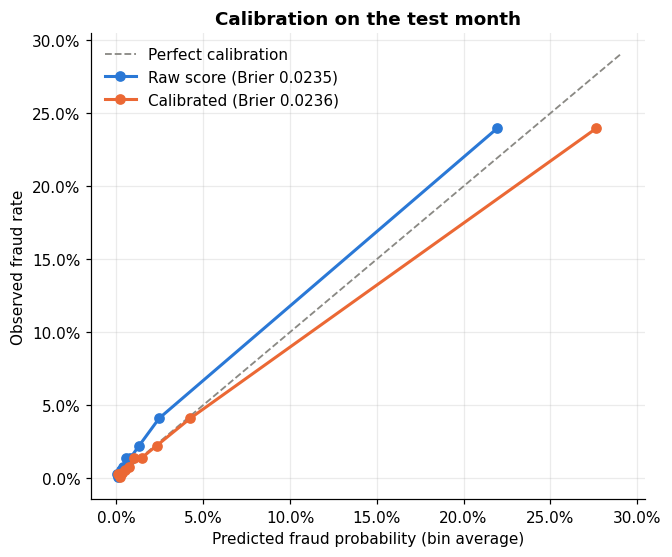

Mean predicted on test: 3.85% vs actual fraud rate 3.50%


In [17]:
def logit(s):
    s = np.clip(np.asarray(s, float), 1e-6, 1 - 1e-6)
    return np.log(s / (1 - s)).reshape(-1, 1)

calibrator = LogisticRegression(C=1e6).fit(logit(val["score"]), val["isFraud"])
val["p"]  = calibrator.predict_proba(logit(val["score"]))[:, 1]
test["p"] = calibrator.predict_proba(logit(test["score"]))[:, 1]

def reliability(frame, col, bins=10):
    q = pd.qcut(frame[col].rank(method="first"), bins, labels=False)
    return frame.groupby(q).agg(predicted=(col, "mean"), observed=("isFraud", "mean"))

rel_raw, rel_cal = reliability(test, "score"), reliability(test, "p")
brier = {c: float(((test[c] - test["isFraud"]) ** 2).mean()) for c in ["score", "p"]}

fig, ax = plt.subplots(figsize=(6.5, 5.5))
lim = max(rel_raw.max().max(), rel_cal.max().max()) * 1.05
ax.plot([0, lim], [0, lim], color=MUTED, ls="--", lw=1.2, label="Perfect calibration")
ax.plot(rel_raw["predicted"], rel_raw["observed"], marker="o", color=GENUINE, label=f"Raw score (Brier {brier['score']:.4f})")
ax.plot(rel_cal["predicted"], rel_cal["observed"], marker="o", color=FRAUD, label=f"Calibrated (Brier {brier['p']:.4f})")
ax.set_xlabel("Predicted fraud probability (bin average)"); ax.set_ylabel("Observed fraud rate")
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_title("Calibration on the test month")
ax.legend(frameon=False)
save(fig, "13_calibration"); plt.show()

print(f"Mean predicted on test: {test['p'].mean():.2%} vs actual fraud rate {test['isFraud'].mean():.2%}")

**Note:** validation had a higher fraud rate (≈4.4%) than test (≈3.5%), so calibrated probabilities may run slightly high on test.
That makes every policy a little *more cautious* than necessary, so the results below are, if anything, conservative.

## 3. The cost model
Every action has an expected dollar cost, which depends on whether the order is really fraud. **All assumptions live in one dictionary**;
they are documented below and become sliders in the Step 6 dashboard.

In [18]:
A = {
    # Fraud that gets through
    "chargeback_fee": 25.0,        # $ per chargeback (processor fees typically $15-$100)
    "vamp_fine": 8.0,              # $ per fraud transaction in a month above Visa's limit
    "vamp_limit": 0.015,           # Visa VAMP merchant threshold
    "target_ratio": 0.005,         # the brief's target
    # Genuine customers we turn away
    "margin": 0.30,                # gross margin lost on a lost sale (assumption)
    "churn_prob": 0.30,            # chance a wrongly declined customer never returns (surveys say ~40%; we discount stated intent)
    "future_margin": 80.0,         # margin from that customer's future orders (~2 orders x $135 x 30%)
    # Step-up verification (SMS one-time code / 3-D Secure)
    "sms_cost": 0.05,              # $ per verification
    "stepup_abandon": 0.10,        # share of genuine customers who give up at the extra step
    "stepup_bypass": 0.10,         # share of fraudsters who get through anyway
    # Manual review
    "review_cost": 5.0,            # analyst time per case (~5 min at ~$60/h loaded cost)
    "analyst_miss": 0.10,          # share of reviewed frauds the analyst approves
    "analyst_wrong_decline": 0.05, # share of reviewed genuine orders the analyst declines
    "review_capacity_per_day": 100,
}

ACTIONS = ["approve", "step_up", "decline", "review"]

def action_costs(p, amt, A, fraud_weight=1.0, friction_penalty=0.0):
    """Expected $ cost of each action (columns = ACTIONS) for orders with fraud probability p.
    With p = the true label (0/1) this gives the realised cost, so one function serves both deciding and scoring.
    fraud_weight > 1 makes missed fraud count extra, and friction_penalty adds $ per genuine customer who is not approved
    instantly. Both are policy dials only: reported costs always use the defaults."""
    p, amt = np.asarray(p, float), np.asarray(amt, float)
    fraud_loss    = (amt + A["chargeback_fee"]) * fraud_weight
    lost_customer = amt * A["margin"] + A["churn_prob"] * A["future_margin"]
    lost_sale     = amt * A["margin"]
    f = (1 - p) * friction_penalty
    return np.column_stack([
        p * fraud_loss,                                                                   # approve
        A["sms_cost"] + p * A["stepup_bypass"] * fraud_loss
                      + (1 - p) * A["stepup_abandon"] * lost_sale + f,                     # step-up
        (1 - p) * lost_customer + f,                                                      # decline
        A["review_cost"] + p * A["analyst_miss"] * fraud_loss
                         + (1 - p) * A["analyst_wrong_decline"] * lost_customer + f,       # review
    ])

pd.DataFrame(action_costs([0, 1], [135, 135], A), columns=ACTIONS, index=["genuine $135 order", "fraud $135 order"]).round(2)

,approve,step_up,decline,review
genuine $135 order,0.0000,4.1000,64.5000,8.2200
fraud $135 order,160.0000,16.0500,0.0000,21.0000


**Reading the table:** approving a genuine order costs nothing, but approving a fraud costs the goods plus the fee.
Declining is the reverse. Step-up and review sit in between: cheap insurance, each with its own leakage.

## 4. Scoring a policy
`evaluate` takes the action chosen for each order and reports what actually happened, using the true labels:
total cost (including Visa fines if the month stays above 1.5%), the **fraud chargeback ratio**, and **customer friction**.

In [19]:
def evaluate(frame, action, A, days=None):
    y, amt = frame["isFraud"].to_numpy(), frame["TransactionAmt"].to_numpy()
    action = np.asarray(action)
    idx = np.arange(len(y))
    base_cost = action_costs(y, amt, A)[idx, action]

    # Expected chargebacks and settled (completed) orders for each action
    bypass, aband = A["stepup_bypass"], A["stepup_abandon"]
    miss, wrong = A["analyst_miss"], A["analyst_wrong_decline"]
    chargebacks = np.choose(action, [y, y * bypass, 0 * y, y * miss])
    settled = np.choose(action, [np.ones_like(y, float), y * bypass + (1 - y) * (1 - aband),
                                 0.0 * y, y * miss + (1 - y) * (1 - wrong)])
    ratio = chargebacks.sum() / settled.sum()
    fines = chargebacks.sum() * A["vamp_fine"] if ratio > A["vamp_limit"] else 0.0

    genuine = y == 0
    lost_genuine = np.choose(action, [0 * y, (1 - y) * aband, (1 - y) * 1.0, (1 - y) * wrong])
    n_days = days or frame["day"].nunique()
    reviews_per_day = pd.Series(action == 3).groupby(frame["day"].to_numpy()).sum()
    return {
        "total_cost": float(base_cost.sum() + fines),
        "fines": float(fines),
        "fraud_ratio": float(ratio),
        "fraud_$_stopped": float(1 - (amt * chargebacks).sum() / (amt * y).sum()),
        "approve_%": float((action == 0).mean()), "step_up_%": float((action == 1).mean()),
        "decline_%": float((action == 2).mean()), "review_%": float((action == 3).mean()),
        "genuine_friction_%": float((action[genuine] != 0).mean()),
        "genuine_instant_approval_%": float((action[genuine] == 0).mean()),
        "genuine_lost_%": float(lost_genuine[genuine].mean()),
        "reviews_per_day_avg": float(reviews_per_day.mean()),
        "reviews_per_day_max": int(reviews_per_day.max()),
        "cost_per_30_days": float((base_cost.sum() + fines) / n_days * 30),
    }

def cap_reviews(candidate, priority, day, cap):
    """Pick at most `cap` candidates per day, highest priority first. Returns a boolean mask."""
    d = pd.DataFrame({"day": day, "prio": np.where(candidate, priority, -np.inf), "cand": candidate})
    d = d.sort_values(["day", "prio"], ascending=[True, False])
    d["rank"] = d.groupby("day").cumcount()
    chosen = d["cand"] & (d["rank"] < cap)
    return chosen.reindex(range(len(d))).to_numpy()

do_nothing = lambda frame: np.zeros(len(frame), dtype=int)

## 5. Policies A and B: three tiers by score
Low score → approve, middle → step-up, high → decline. Within the high tier, the **least certain** orders
(lowest scores, the ones most likely to be genuine) go to an analyst, up to 100 a day; the rest are declined automatically.

In [20]:
def tier_policy(frame, t_low, t_high, A):
    p, day = frame["p"].to_numpy(), frame["day"].to_numpy()
    action = np.where(p < t_low, 0, np.where(p < t_high, 1, 2))
    reviewed = cap_reviews(action == 2, -p, day, A["review_capacity_per_day"])
    action[reviewed] = 3
    return action

# Policy A: textbook cut-offs
policy_A = lambda frame: tier_policy(frame, 0.30, 0.75, A)

# Policy B: search cut-offs on VALIDATION, defined by the share of orders flagged
rates = np.geomspace(0.002, 0.4, 28)
cuts = np.quantile(val["p"], 1 - rates)
grid = []
for i, t_low in enumerate(cuts):
    for t_high in cuts[: i + 1]:            # t_high >= t_low
        r = evaluate(val, tier_policy(val, t_low, t_high, A), A)
        grid.append({"t_low": t_low, "t_high": t_high, **r})
grid = pd.DataFrame(grid).sort_values("total_cost")
best_B = grid.iloc[0]
policy_B = lambda frame: tier_policy(frame, best_B["t_low"], best_B["t_high"], A)

print(f"Optimised cut-offs (chosen on validation): step-up from p >= {best_B['t_low']:.3f}, decline/review from p >= {best_B['t_high']:.3f}")
grid.head(5)[["t_low", "t_high", "total_cost", "fraud_ratio", "genuine_friction_%"]]

Optimised cut-offs (chosen on validation): step-up from p >= 0.034, decline/review from p >= 0.989


,t_low,t_high,total_cost,fraud_ratio,genuine_friction_%
276,0.0338,0.9886,"168,633.4932",0.0108,0.1521
277,0.0338,0.9874,"168,767.1432",0.0108,0.1521
300,0.0265,0.9886,"168,805.9982",0.0097,0.1923
278,0.0338,0.9858,"168,924.6446",0.0108,0.1521
301,0.0265,0.9874,"168,939.6482",0.0097,0.1923


## 6. Policy C: the expected-cost decision rule
Instead of cutting on score alone, every order gets the action with the **lowest expected cost**, which depends on **both**
fraud probability and order amount. A 40%-risk $900 order can deserve more caution than a 90%-risk $20 order.

Review slots go to the orders where an analyst saves the most money versus the next-best automatic action, 100 a day.

In [21]:
def expected_cost_policy(frame, A, fraud_weight=1.0, friction_penalty=0.0):
    p, amt, day = frame["p"].to_numpy(), frame["TransactionAmt"].to_numpy(), frame["day"].to_numpy()
    C = action_costs(p, amt, A, fraud_weight, friction_penalty)
    auto_best = C[:, :3].argmin(axis=1)                 # best action without an analyst
    review_saving = C[:, :3].min(axis=1) - C[:, 3]      # $ an analyst saves on this order
    reviewed = cap_reviews(review_saving > 0, review_saving, day, A["review_capacity_per_day"])
    return np.where(reviewed, 3, auto_best)

policy_C = lambda frame: expected_cost_policy(frame, A)
pd.Series(evaluate(val, policy_C(val), A)).to_frame("validation")

,validation
total_cost,"152,504.8908"
fines,0.0000
fraud_ratio,0.0080
fraud_$_stopped,0.8099
approve_%,0.7527
step_up_%,0.2186
decline_%,0.0140
review_%,0.0148
genuine_friction_%,0.2183
genuine_instant_approval_%,0.7817


## 7. Policy D: respecting the brief's friction limit
Policy C may step up a large share of genuine customers, because a step-up looks cheap in the cost model (an SMS plus a small chance
of abandonment). But the brief requires **at least 90% of genuine customers approved instantly**, since constant verification
erodes trust in ways the cost model can't fully price.

We add a **friction penalty** (a $ amount per genuine customer who doesn't get instant approval) and pick the **smallest penalty
that meets 90% on validation**. This is the same idea as a budget: the policy still minimises cost, but within a friction limit.

In [22]:
FRICTION_LIMIT = 0.10   # at most 10% of genuine customers may face an extra step

def tune_friction(frame, A, limit=FRICTION_LIMIT):
    for f in [0, 1, 2, 4, 6, 8, 12, 16, 24, 32, 48, 64, 96, 128, 192, 256]:
        r = evaluate(frame, expected_cost_policy(frame, A, friction_penalty=f), A)
        if r["genuine_friction_%"] <= limit:
            return float(f)
    return float(f)

f_D = tune_friction(val, A)
policy_D = lambda frame: expected_cost_policy(frame, A, friction_penalty=f_D)
print(f"Friction penalty chosen on validation: ${f_D:.0f} per genuine customer not approved instantly")
pd.DataFrame({"C (unconstrained)": evaluate(val, policy_C(val), A),
              "D (friction limit)": evaluate(val, policy_D(val), A)})

Friction penalty chosen on validation: $4 per genuine customer not approved instantly


,C (unconstrained),D (friction limit)
total_cost,"152,504.8908","164,976.7051"
fines,0.0000,0.0000
fraud_ratio,0.0080,0.0127
fraud_$_stopped,0.8099,0.7586
approve_%,0.7527,0.8843
step_up_%,0.2186,0.0891
decline_%,0.0140,0.0140
review_%,0.0148,0.0127
genuine_friction_%,0.2183,0.0861
genuine_instant_approval_%,0.7817,0.9139


## 8. Policy E: what does the 0.5% target cost?
Policy C minimises cost, but may not reach the brief's 0.5% fraud ratio. We make it stricter by counting missed fraud
as more expensive (a "compliance weight"), and pick the **smallest weight that meets 0.5% on validation**.
Sweeping the weight also traces the **trade-off curve** between fraud ratio and customer friction.

In [23]:
weights = [1, 1.5, 2, 3, 4, 6, 8, 12, 16, 24, 32, 48, 64, 100]
sweep = []
for w in weights:
    rv = evaluate(val, expected_cost_policy(val, A, w), A)
    rt = evaluate(test, expected_cost_policy(test, A, w), A)
    sweep.append({"weight": w, "val_fraud_ratio": rv["fraud_ratio"], "val_cost": rv["total_cost"],
                  "test_fraud_ratio": rt["fraud_ratio"], "test_friction": rt["genuine_friction_%"],
                  "test_cost_30d": rt["cost_per_30_days"]})
sweep = pd.DataFrame(sweep)

meets = sweep[sweep["val_fraud_ratio"] <= A["target_ratio"]]
if len(meets):
    w_E = float(meets["weight"].iloc[0])
    print(f"Smallest weight meeting 0.5% on validation: {w_E}")
else:
    w_E = float(sweep["weight"].iloc[-1])
    print(f"No weight up to {w_E} reaches 0.5% on validation; using the strictest one tested.")
policy_E = lambda frame: expected_cost_policy(frame, A, w_E)
sweep

Smallest weight meeting 0.5% on validation: 3.0


,weight,val_fraud_ratio,val_cost,test_fraud_ratio,test_friction,test_cost_30d
0,1.0000,0.0080,"152,504.8908",0.0085,0.2226,"210,469.0689"
1,1.5000,0.0063,"155,956.1799",0.0069,0.3071,"218,432.3572"
2,2.0000,0.0051,"160,882.3405",0.0059,0.3782,"230,260.9672"
3,3.0000,0.0042,"178,272.5590",0.0045,0.4938,"256,871.3133"
4,4.0000,0.0037,"195,192.8160",0.0039,0.5792,"279,473.6919"
5,6.0000,0.0031,"223,516.6201",0.0032,0.6920,"322,984.2381"
6,8.0000,0.0028,"243,361.1425",0.0028,0.7662,"352,043.7290"
7,12.0000,0.0024,"278,891.9832",0.0025,0.8506,"407,768.8810"
8,16.0000,0.0022,"307,097.3470",0.0024,0.8994,"459,901.5698"
9,24.0000,0.0019,"361,668.0906",0.0020,0.9454,"546,203.1072"


## 9. Results on the test month

In [24]:
policies = {
    "0. Do nothing": do_nothing,
    "A. Naive thresholds (0.30 / 0.75)": policy_A,
    "B. Optimised thresholds": policy_B,
    "C. Expected-cost policy": policy_C,
    "D. Expected-cost within limits": policy_D,
    "E. Expected-cost + 0.5% target": policy_E,
}
results = pd.DataFrame({name: evaluate(test, f(test), A) for name, f in policies.items()}).T
base = results.loc["0. Do nothing", "cost_per_30_days"]
results["saving_per_30_days"] = base - results["cost_per_30_days"]
results["saving_%"] = results["saving_per_30_days"] / base

show = results[["cost_per_30_days", "saving_per_30_days", "saving_%", "fraud_ratio", "fraud_$_stopped",
                "genuine_instant_approval_%", "genuine_lost_%", "reviews_per_day_avg", "reviews_per_day_max"]]
show.style.format({
    "cost_per_30_days": "${:,.0f}", "saving_per_30_days": "${:,.0f}", "saving_%": "{:.0%}",
    "fraud_ratio": "{:.2%}", "fraud_$_stopped": "{:.0%}", "genuine_instant_approval_%": "{:.1%}",
    "genuine_lost_%": "{:.2%}", "reviews_per_day_avg": "{:.0f}", "reviews_per_day_max": "{:.0f}",
})

,cost_per_30_days,saving_per_30_days,saving_%,fraud_ratio,fraud_$_stopped,genuine_instant_approval_%,genuine_lost_%,reviews_per_day_avg,reviews_per_day_max
0. Do nothing,"$556,238",$0,0%,3.50%,0%,100.0%,0.00%,0,0
A. Naive thresholds (0.30 / 0.75),"$405,209","$151,029",27%,2.17%,27%,98.8%,0.11%,33,64
B. Optimised thresholds,"$224,738","$331,500",60%,1.08%,70%,84.6%,1.54%,4,20
C. Expected-cost policy,"$210,469","$345,769",62%,0.85%,76%,77.7%,2.29%,45,70
D. Expected-cost within limits,"$221,985","$334,252",60%,1.27%,69%,91.3%,0.94%,39,58
E. Expected-cost + 0.5% target,"$256,871","$299,366",54%,0.45%,87%,50.6%,5.13%,88,100


**Column guide:** *fraud_ratio* = chargebacks ÷ completed orders (what Visa monitors). *genuine_instant_approval_%* = genuine customers
approved with no extra step (brief target: ≥ 90%). *genuine_lost_%* = genuine customers who ended up without their order (declined, abandoned, or wrongly
rejected by an analyst).

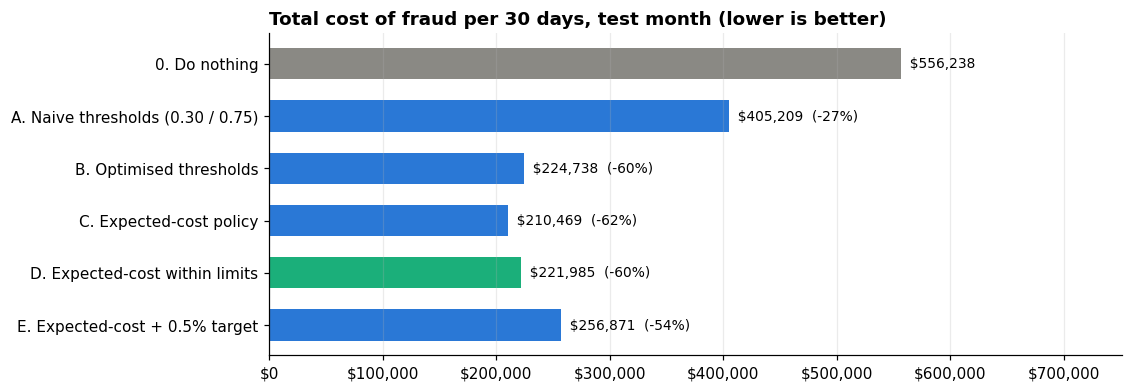

In [25]:
order = list(policies)[::-1]
vals = results.loc[order, "cost_per_30_days"]
colors = [MUTED if n.startswith("0.") else (ACCENT if n.startswith("D.") else GENUINE) for n in order]

fig, ax = plt.subplots(figsize=(10, 3.8))
ax.barh(order, vals, color=colors, height=0.6)
for y, (n, v) in enumerate(vals.items()):
    label = f"  ${v:,.0f}" + ("" if n.startswith("0.") else f"  (-{results.loc[n, 'saving_%']:.0%})")
    ax.text(v, y, label, va="center", fontsize=9)
ax.set_xlim(0, vals.max() * 1.35)
ax.xaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.grid(axis="y", visible=False)
ax.set_title("Total cost of fraud per 30 days, test month (lower is better)", loc="left")
save(fig, "14_policy_cost_comparison"); plt.show()

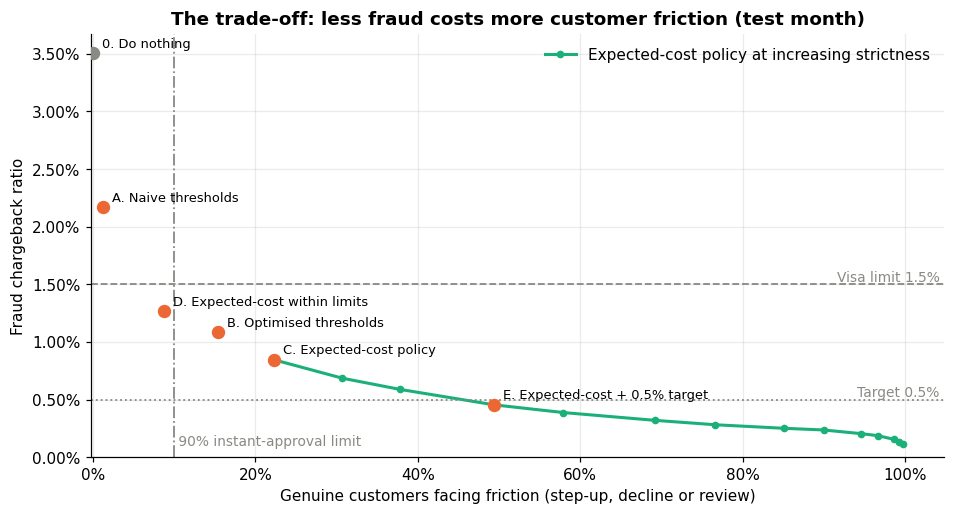

In [26]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(sweep["test_friction"], sweep["test_fraud_ratio"], color=ACCENT, marker="o", ms=4,
        label="Expected-cost policy at increasing strictness")
for name in policies:
    r = results.loc[name]
    ax.scatter(r["genuine_friction_%"], r["fraud_ratio"], s=60, zorder=3,
               color=MUTED if name.startswith("0.") else FRAUD)
    ax.annotate(name.split(" (")[0], (r["genuine_friction_%"], r["fraud_ratio"]),
                xytext=(6, 4), textcoords="offset points", fontsize=8.5)
ax.axhline(A["vamp_limit"], color=MUTED, ls="--", lw=1.2)
ax.axhline(A["target_ratio"], color=MUTED, ls=":", lw=1.2)
ax.axvline(FRICTION_LIMIT, color=MUTED, ls="-.", lw=1.2)
ax.set_ylim(0, None)
ax.text(FRICTION_LIMIT, ax.get_ylim()[1] * 0.02, " 90% instant-approval limit", fontsize=9, color=MUTED, va="bottom")
ax.text(ax.get_xlim()[1], A["vamp_limit"], "Visa limit 1.5% ", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.text(ax.get_xlim()[1], A["target_ratio"], "Target 0.5% ", ha="right", va="bottom", fontsize=9, color=MUTED)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0)); ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
ax.set_ylim(0, None); ax.set_xlim(left=-0.002)
ax.set_xlabel("Genuine customers facing friction (step-up, decline or review)")
ax.set_ylabel("Fraud chargeback ratio")
ax.set_title("The trade-off: less fraud costs more customer friction (test month)")
ax.legend(frameon=False, loc="upper right")
save(fig, "15_fraud_vs_friction_tradeoff"); plt.show()

## 10. How sensitive is the result to our assumptions?
The costs are assumptions, so we re-run the recommended Policy D under different values: the friction penalty is re-tuned on validation
for each scenario and every test order is re-decided.
If the savings hold across reasonable ranges, the conclusion is robust.

In [27]:
scenarios = {
    "Base case": {},
    "Step-up abandonment 20% (vs 10%)": {"stepup_abandon": 0.20},
    "Step-up abandonment 5%": {"stepup_abandon": 0.05},
    "Chargeback fee $50 (vs $25)": {"chargeback_fee": 50.0},
    "Margin 15% (vs 30%)": {"margin": 0.15},
    "Customer churn 45% (vs 30%)": {"churn_prob": 0.45},
    "Review capacity 50/day (vs 100)": {"review_capacity_per_day": 50},
}
rows = []
for name, change in scenarios.items():
    A_s = {**A, **change}
    nothing = evaluate(test, do_nothing(test), A_s)["cost_per_30_days"]
    f_s = tune_friction(val, A_s)
    r = evaluate(test, expected_cost_policy(test, A_s, friction_penalty=f_s), A_s)
    rows.append({"scenario": name, "cost_per_30_days": r["cost_per_30_days"], "saving_%": 1 - r["cost_per_30_days"] / nothing,
                 "fraud_ratio": r["fraud_ratio"], "genuine_instant_approval_%": r["genuine_instant_approval_%"]})
sens = pd.DataFrame(rows).set_index("scenario")
sens.style.format({"cost_per_30_days": "${:,.0f}", "saving_%": "{:.0%}", "fraud_ratio": "{:.2%}", "genuine_instant_approval_%": "{:.1%}"})

,cost_per_30_days,saving_%,fraud_ratio,genuine_instant_approval_%
scenario,,,,
Base case,"$221,985",60%,1.27%,91.3%
Step-up abandonment 20% (vs 10%),"$232,826",58%,1.18%,90.1%
Step-up abandonment 5%,"$198,225",64%,1.30%,91.2%
Chargeback fee $50 (vs $25),"$251,572",60%,1.28%,91.6%
Margin 15% (vs 30%),"$197,896",64%,1.30%,91.1%
Customer churn 45% (vs 30%),"$223,582",60%,1.27%,91.3%
Review capacity 50/day (vs 100),"$221,867",60%,1.27%,91.3%


## 11. Save results, and data for the Step 6 dashboard
- `reports/step4_results.json`: every number above.
- `app/test_scores.csv.gz`: the test month's orders with calibrated probabilities (small: ~1-2 MB). The dashboard re-runs the policy live from this file.
- `app/assumptions.json`: the cost assumptions, as the dashboard's starting values.

In [28]:
(test[["TransactionID", "day", "TransactionAmt", "isFraud", "p"]]
     .round({"p": 6, "TransactionAmt": 3})
     .to_csv(APP_DIR / "test_scores.csv.gz", index=False, compression="gzip"))
(APP_DIR / "assumptions.json").write_text(json.dumps(A, indent=2))

summary = {
    "calibration": {"brier_raw": brier["score"], "brier_calibrated": brier["p"]},
    "policy_B_cutoffs": {"step_up_from": float(best_B["t_low"]), "decline_or_review_from": float(best_B["t_high"])},
    "policy_D_friction_penalty": f_D,
    "policy_E_weight": w_E,
    "results_test": {k: {c: float(v) for c, v in row.items()} for k, row in results.iterrows()},
    "sensitivity_policy_D": {k: {c: float(v) for c, v in row.items()} for k, row in sens.iterrows()},
    "assumptions": A,
}
(OUT_DIR / "step4_results.json").write_text(json.dumps(summary, indent=2))
print(json.dumps({k: summary[k] for k in ["policy_B_cutoffs", "policy_D_friction_penalty", "policy_E_weight",
                                          "results_test", "sensitivity_policy_D"]}, indent=2))

{
  "policy_B_cutoffs": {
    "step_up_from": 0.033766319134166646,
    "decline_or_review_from": 0.9885660334461903
  },
  "policy_D_friction_penalty": 4.0,
  "policy_E_weight": 3.0,
  "results_test": {
    "0. Do nothing": {
      "total_cost": 556237.576,
      "fines": 23952.0,
      "fraud_ratio": 0.03504623668500527,
      "fraud_$_stopped": 0.0,
      "approve_%": 1.0,
      "step_up_%": 0.0,
      "decline_%": 0.0,
      "review_%": 0.0,
      "genuine_friction_%": 0.0,
      "genuine_instant_approval_%": 1.0,
      "genuine_lost_%": 0.0,
      "reviews_per_day_avg": 0.0,
      "reviews_per_day_max": 0.0,
      "cost_per_30_days": 556237.576,
      "saving_per_30_days": 0.0,
      "saving_%": 0.0
    },
    "A. Naive thresholds (0.30 / 0.75)": {
      "total_cost": 405208.6284749999,
      "fines": 14592.0,
      "fraud_ratio": 0.021671214176110697,
      "fraud_$_stopped": 0.26683682512704254,
      "approve_%": 0.9728783799602013,
      "step_up_%": 0.015498068594170666,
    

## Findings

- **The recommended policy (D) cuts the total cost of fraud by 60%**: from $556k to $222k per 30 days (about $334k a month saved, roughly $4M a year). The fraud ratio falls from 3.50% to **1.27%, below Visa's 1.5% limit** (no network fines), while **91.3% of genuine customers are approved instantly** and the review queue peaks at 58 a day (cap 100).
- **Textbook thresholds fail.** The 0.30 / 0.75 rule saves only 27% and leaves NovaCart at 2.17%, still above Visa's limit and still paying fines.
- **Amount-aware decisions beat score-only cut-offs.** Optimised thresholds (B) and the expected-cost policy within limits (D) cost about the same ($225k vs $222k), but D approves 91% of genuine customers instantly vs 85% for B, because it weighs fraud probability *and* order value.
- **Customer experience is cheap to protect.** The unconstrained optimum (C) is only $11k a month cheaper than D, but puts 22% of genuine customers through extra checks instead of 9%.
- **The 0.5% target is reachable, but not worth it with this model.** Policy E reaches 0.45%, but only half of genuine customers are approved instantly, 5% are lost (vs 0.9% for D), and it costs $35k a month more than D. Recommendation: adopt D now; pursue 0.5% through a better model (e.g. identity data), not stricter rules.
- **The result is robust.** Across 7 alternative assumptions (step-up abandonment, chargeback fees, margin, churn, review capacity), savings stay between 58% and 64%.
- **Caveat:** D's 1.27% sits close to Visa's 1.5% limit, so ongoing monitoring and model improvement are needed.

**Next:** Step 5 explains individual decisions with SHAP ("why was this order stepped up?").